# Q8A — Clusterização do desempenho multidisciplinar: metodologia e seleção do algoritmo

**Projeto:** ENEM — Pará (PA)  
**Período:** 2009–2023  
**Referência territorial:** ESC  
**Unidade de análise:** município por edição

**OBJETIVO**

Investigar e selecionar uma estratégia de clusterização capaz de identificar perfis municipais semelhantes considerando simultaneamente 
as cinco áreas do ENEM: Ciências Humanas,Ciências da Natureza,,Linguagens e Códigos ,Matemática (MT) e Redação. Este notebook documenta a fundamentação, prepara o conjunto analítico e compara algoritmos candidatos. A aplicação longitudinal do método selecionado, a interpretação dos perfis e a análise das transições serão desenvolvidas  [`Q8B_CLUSTERINGS_APLICACAO`](Q8B_CLUSTERINGS_APLICACAO.ipynb) 


<div style="background-color: #b7e3a8; padding: 12px; border-radius: 6px;">

#### **Os municípios paraenses podem ser agrupados em perfis semelhantes de desempenho multidisciplinar no ENEM?**

A dimensão temporal será tratada por agrupamentos independentes em cada edição. Assim, os grupos representam posições relativas entre municípios no mesmo ano, e não níveis absolutos diretamente comparáveis entre anos.

</div>

\
**DELIMITAÇÃO METODOLOGICA**

- Período: 2009–2023;
- coorte balanceada: 37 municípios com dados completos nas 15 edições;
- cinco disciplinas como variáveis de entrada;
- critério operacional de elegibilidade: mais de 100 participantes;
- padronização das cinco variáveis separadamente em cada edição;
- variáveis de participação, sexo, faixa etária e dependência administrativa não entram na clusterização. Poderão ser usadas posteriormente para caracterizar os grupos.

<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">

**ATENÇÃO:** O agrupamento identifica semelhanças nas variáveis selecionadas. Não classifica municípios como bons ou ruins e não permite inferência causal sobre fatores associados ao desempenho.
</div>

----
### Por que clusterizar?

As análises anteriores já investigaram evolução das médias, dispersão territorial, desigualdades entre grupos, participação e associações entre indicadores. A lacuna complementar é examinar o desempenho municipal de forma multidimensional e simultânea.

Uma análise univariada ou bivariada pode mostrar, por exemplo, municípios com médias próximas em Matemática ou diferenças entre redes. A clusterização considera conjuntamente o vetor de cinco notas de cada município e procura identificar municípios com padrões de desempenho semelhantes.

### Representação dos dados

Para cada edição \(t\), cada município \(i\) será representado por:
$$ 
\mathbf{x}_{i,t} =
[CH_{i,t}, CN_{i,t}, LC_{i,t}, MT_{i,t}, RD_{i,t}]
 $$

O conjunto de cada edição terá 37 observações e cinco variáveis, após a validação da coorte balanceada.

### Por que padronizar dentro de cada edição?

As escalas e dispersões das disciplinas diferem. A padronização por edição transforma cada variável em uma medida relativa à distribuição municipal daquele ano:
$$
z_{i,j,t} = \frac{x_{i,j,t} - \bar{x}_{j,t}}{s_{j,t}}
$$
Isso evita que uma disciplina com maior variabilidade numérica domine automaticamente as distâncias. Também significa que os clusters descrevem posições relativas em cada edição. A comparação temporal deverá considerar a composição e o perfil dos grupos, não uma suposta equivalência absoluta dos rótulos.

---

## Configurações e carga

In [13]:
from _setup2 import *

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

from utils.utils_ML import (DISCIPLINAS_ENEM_2009,preparar_painel_municipal,avaliar_particao_clusters)
sns.set_theme(style="whitegrid", context="notebook")


UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"
ANOS = list(range(2009, 2024))
ANO_INICIAL, ANO_FINAL = ANOS[0], ANOS[-1]
N_MINIMO_PARTICIPANTES = 100
K_CANDIDATOS = range(2, 7)
K_COMPARACAO = [2, 3, 4]
RANDOM_STATE = 42
N_INIT = 50

DISCIPLINAS = list(DISCIPLINAS_ENEM_2009)



out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel = out["painel"]["data"].copy()
dsp = out["dsp"]["data"].copy()

print(f"Painel: {painel.shape[0]:,} linhas × {painel.shape[1]} colunas")
print(f"DSP: {dsp.shape[0]:,} linhas × {dsp.shape[1]} colunas")

print("=" * 66)
print(f"UF           : {UF_PROCESSAMENTO}  | Período: {ANO_INICIAL}–{ANO_FINAL}| Referência: {TIPO_REFERENCIA} ")
print(f"DISCIPLINAS  : {', '.join(DISCIPLINAS)}")
print(f"painel       : {painel.shape[0]:,} x {painel.shape[1]}".replace(",", "."))
print(f"dsp          : {dsp.shape[0]:,} x {dsp.shape[1]}".replace(",", "."))
print("=" * 66)


Painel: 3,625 linhas × 82 colunas
DSP: 250,436 linhas × 17 colunas
UF           : PA  | Período: 2009–2023| Referência: ESC 
DISCIPLINAS  : CH, CN, LC, MT, REDACAO
painel       : 3.625 x 82
dsp          : 250.436 x 17


## 1. Construção e validação da corte balanceada

In [2]:
# DESEMPENHO MUNCPAL
desempenho_municipal = eda2.preparar_desempenho_territorial_dsp(dsp,referencia=TIPO_REFERENCIA,
                                                                n_minimo_participantes=N_MINIMO_PARTICIPANTES,
                                                                anos_inicio_comparavel=2002,painel=painel)
# PAINEL MUNICPAL

painel_municipal = preparar_painel_municipal(desempenho_municipal,anos=ANOS,disciplinas=DISCIPLINAS,exigir_elegibilidade=True)

municipios_por_ano = {ano: set(painel_municipal.loc[
            painel_municipal["ano"].eq(ano)& painel_municipal["media_geral_5_disciplinas"].notna(),"CO_MUNICIPIO_TERRITORIO"])
    for ano in ANOS}


# BALANCEAMENTO

municipios_balanceados = set.intersection(*(municipios_por_ano[a] for a in ANOS))
painel_balanceado = painel_municipal.loc[painel_municipal["CO_MUNICIPIO_TERRITORIO"].isin(municipios_balanceados)].copy()

n_municipios = len(municipios_balanceados)
if n_municipios != 37 or len(painel_balanceado) != 37 * len(ANOS):
    raise ValueError(
        f"Coorte inesperada: {n_municipios} municípios e {len(painel_balanceado)} linhas. "
        "Esperado: 37 municípios e 555 observações.")
if painel_balanceado.duplicated(["CO_MUNICIPIO_TERRITORIO", "ano"]).any():
    raise ValueError("Há duplicidade de município-ano na coorte balanceada.")

cobertura_anual = painel_balanceado.groupby("ano").agg(
    municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
    observacoes=("CO_MUNICIPIO_TERRITORIO", "size"))

print(f"Corte validada: {n_municipios} municípios × {len(ANOS)} edições = {len(painel_balanceado)} observações.")

Corte validada: 37 municípios × 15 edições = 555 observações.


## 2. Padronização das variáveis por edição


Matrizes anuais: 15 | dimensão: (37, 5)


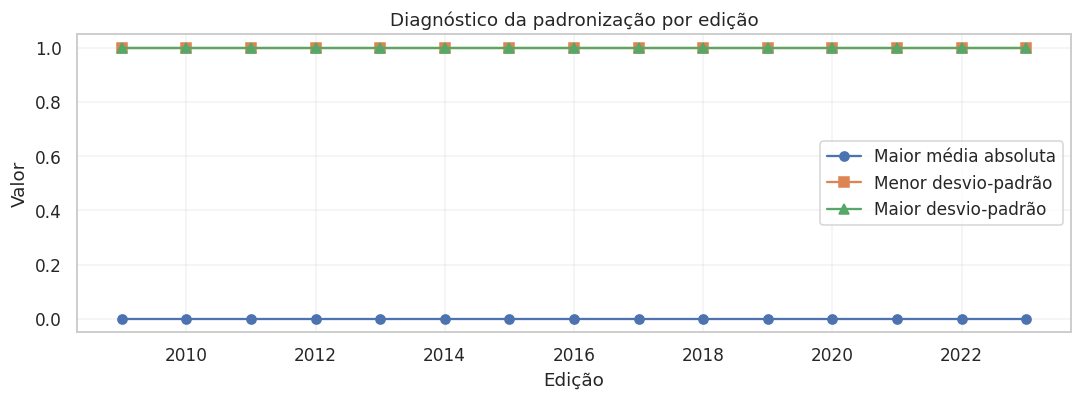

In [3]:
MATRIZES_ANUAIS = {}
for ano in ANOS:
    dados_ano = (
        painel_balanceado.loc[painel_balanceado["ano"].eq(ano),["CO_MUNICIPIO_TERRITORIO", "NO_MUNICIPIO_TERRITORIO"] + DISCIPLINAS]
            .sort_values("CO_MUNICIPIO_TERRITORIO").copy())
    X = dados_ano[DISCIPLINAS].astype(float)
    if X.isna().any().any():
        raise ValueError(f"Há valores ausentes nas disciplinas em {ano}.")
    X_scaled = StandardScaler().fit_transform(X)
    MATRIZES_ANUAIS[ano] = {
        "municipios": dados_ano[["CO_MUNICIPIO_TERRITORIO", "NO_MUNICIPIO_TERRITORIO"]].reset_index(drop=True),
        "X": X.to_numpy(),
        "X_scaled": X_scaled}

print(f"Matrizes anuais: {len(MATRIZES_ANUAIS)} | dimensão: {MATRIZES_ANUAIS[ANOS[0]]['X_scaled'].shape}")

diagnostico_scaling = pd.DataFrame([{"ano": ano,
                                     "n_municipios": dados["X_scaled"].shape[0],
                                     "n_variaveis": dados["X_scaled"].shape[1],
                                     "maior_media_abs": np.abs(dados["X_scaled"].mean(axis=0)).max(),
                                     "menor_dp": dados["X_scaled"].std(axis=0, ddof=0).min(),
                                     "maior_dp": dados["X_scaled"].std(axis=0, ddof=0).max()}
                                    for ano, dados in MATRIZES_ANUAIS.items()])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(diagnostico_scaling["ano"], diagnostico_scaling["maior_media_abs"], marker="o", label="Maior média absoluta")
ax.plot(diagnostico_scaling["ano"], diagnostico_scaling["menor_dp"], marker="s", label="Menor desvio-padrão")
ax.plot(diagnostico_scaling["ano"], diagnostico_scaling["maior_dp"], marker="^", label="Maior desvio-padrão")
ax.set(title="Diagnóstico da padronização por edição", xlabel="Edição", ylabel="Valor")
ax.grid(alpha=.25);
ax.legend(); 
plt.tight_layout(); plt.show()



### Comentários

A padronização foi realizada separadamente em cada ano, sobre as mesmas 37 unidades municipais e as cinco disciplinas.
Assim, cada matriz anual contém 37 municípios e cinco variáveis transformadas em escores padronizados.

Essa preparação mantém a comparação entre algoritmos dentro de cada edição e impede que diferenças de escala entre disciplinas determinem isoladamente as distâncias. Os perfis resultantes devem ser interpretados como posições relativas à distribuição municipal do respectivo ano, não como níveis absolutos comparáveis diretamente entre edições.

## 3. Competição entre algoritmos

### A. Algoritmos candidatos

A competição considera métodos com pressupostos diferentes. Nenhum algoritmo será escolhido apenas por apresentar a maior métrica isolada.

| Método | Lógica | Pontos fortes | Limitações relevantes |
|---|---|---|---|
| **K-Means** | Minimiza a distância quadrática aos centroides | Simples, rápido e interpretável | Exige K; sensível a outliers e à inicialização |
| **Aglomerativo (Ward)** | Agrupa observações hierarquicamente, minimizando aumento da variância intragrupo | Permite examinar estrutura hierárquica; não exige inicialização aleatória | Exige definir o número final de grupos; Ward favorece grupos compactos |
| **Gaussian Mixture (GMM)** | Modela os dados como mistura de distribuições gaussianas | Atribui probabilidades de pertencimento; formas elípticas | Pressupõe estrutura probabilística; pode ser instável em amostras pequenas |
| **DBSCAN** | Identifica regiões densas e pontos considerados ruído | Não exige K previamente; detecta ruído | Sensível a `eps` e `min_samples`; pode não encontrar estrutura em amostras pequenas |

### B. Estratégia de comparação

- K-Means, Aglomerativo e GMM: testar \(K=2,\ldots,6\).
- DBSCAN: testar uma grade curta de `eps` e `min_samples`, registrando ruído e configurações sem solução válida.
- Avaliar cada configuração em cada edição, usando as mesmas 37 observações e as mesmas cinco variáveis padronizadas.
- Comparar métricas internas, número e tamanho dos grupos, frequência de soluções válidas e interpretabilidade.

As métricas internas não demonstram que os grupos sejam verdadeiros ou naturais. Elas apenas ajudam a comparar partições possíveis.

As configurações são ajustadas separadamente em cada edição. As métricas são calculadas pela função `avaliar_particao_clusters`, centralizada no módulo do projeto. Para DBSCAN, os pontos classificados como ruído são contabilizados separadamente.
### C. Métricas e critérios de decisão

#### Métricas internas

- **Silhouette:** maior é melhor; combina coesão e separação. Requer pelo menos dois grupos e menos grupos que observações.
- **Calinski–Harabasz:** maior é melhor; compara dispersão entre grupos e dentro dos grupos.
- **Davies–Bouldin:** menor é melhor; avalia semelhança entre grupos.
- **Inércia:** disponível para K-Means; diminui com K e deve ser interpretada pelo cotovelo, não pelo menor valor isolado.
- **AIC/BIC:** disponíveis para GMM; menores valores indicam melhor equilíbrio entre ajuste e complexidade dentro da família de modelos.

### Critérios substantivos

1. Frequência de soluções válidas nas 15 edições.
2. Ausência de grupos excessivamente pequenos ou partições muito desequilibradas.
3. Coerência dos perfis médios nas cinco disciplinas.
4. Simplicidade e reprodutibilidade.
5. Possibilidade de acompanhar a reorganização relativa dos municípios ao longo do tempo.


In [4]:
# KMEANS
resultados_kmeans = []
for ano in ANOS:
    X = MATRIZES_ANUAIS[ano]["X_scaled"]
    for k in K_CANDIDATOS:
        modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
        labels = modelo.fit_predict(X)
        resultados_kmeans.append({
            "ano": ano, "algoritmo": "KMeans", "configuracao": f"k={k}",
            "k_solicitado": k, "inercia": modelo.inertia_,
            **avaliar_particao_clusters(X, labels),
        })
resultados_kmeans = pd.DataFrame(resultados_kmeans)

# AGGLOMERATIVE CLUSTERING

resultados_aglomerativo = []
for ano in ANOS:
    X = MATRIZES_ANUAIS[ano]["X_scaled"]
    for k in K_CANDIDATOS:
        labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        resultados_aglomerativo.append({
            "ano": ano, "algoritmo": "Aglomerativo_Ward", "configuracao": f"k={k}",
            "k_solicitado": k, "inercia": np.nan,
            **avaliar_particao_clusters(X, labels),
        })
resultados_aglomerativo = pd.DataFrame(resultados_aglomerativo)

# GAUSSIAN MIXTURE (GMM)

resultados_gmm = []
for ano in ANOS:
    X = MATRIZES_ANUAIS[ano]["X_scaled"]
    for k in K_CANDIDATOS:
        modelo = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE, n_init=10, reg_covar=1e-5)
        labels = modelo.fit_predict(X)
        resultados_gmm.append({
            "ano": ano, "algoritmo": "GMM", "configuracao": f"k={k}",
            "k_solicitado": k, "aic": modelo.aic(X), "bic": modelo.bic(X),
            **avaliar_particao_clusters(X, labels),
        })
resultados_gmm = pd.DataFrame(resultados_gmm)


# DBSCAN

EPS_CANDIDATOS = [0.8, 1.0, 1.2, 1.5, 1.8, 2.0]
MIN_SAMPLES_CANDIDATOS = [3, 4, 5]
resultados_dbscan = []
for ano in ANOS:
    X = MATRIZES_ANUAIS[ano]["X_scaled"]
    for eps in EPS_CANDIDATOS:
        for min_samples in MIN_SAMPLES_CANDIDATOS:
            labels = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean").fit_predict(X)
            resultados_dbscan.append({
                "ano": ano, "algoritmo": "DBSCAN",
                "configuracao": f"eps={eps}; min_samples={min_samples}",
                "k_solicitado": np.nan, "eps": eps, "min_samples": min_samples,
                **avaliar_particao_clusters(X, labels),
            })
            
resultados_dbscan = pd.DataFrame(resultados_dbscan)

resultados_competicao = pd.concat(
    [resultados_kmeans, resultados_aglomerativo, resultados_gmm, resultados_dbscan],ignore_index=True, sort=False)

print(f"Configurações avaliadas: {len(resultados_competicao):,} (15 edições).")

Configurações avaliadas: 495 (15 edições).


## 4. Síntese da competição


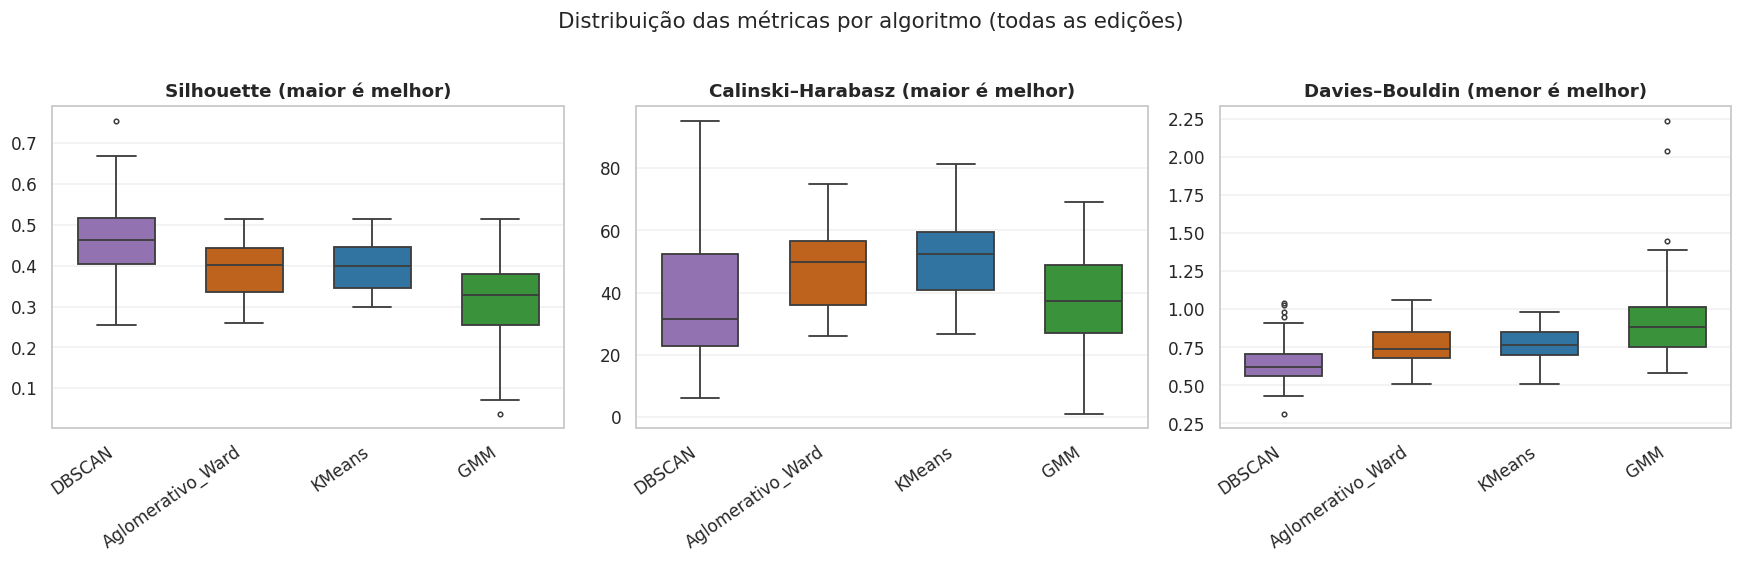

In [5]:
resumo_algoritmos = (resultados_competicao.groupby("algoritmo").agg(
        configuracoes=("configuracao", "count"),
        solucoes_avaliaveis=("silhouette", "count"),
        silhouette_mediana=("silhouette", "median"),
        calinski_mediana=("calinski_harabasz", "median"),
        davies_bouldin_mediana=("davies_bouldin", "median"),
        clusters_mediana=("n_clusters", "median"),
        menor_cluster_mediano=("n_menor_cluster", "median"),
        ruido_mediano=("prop_ruido", "median")).reset_index())

resumo_algoritmos["taxa_solucoes_avaliaveis"] = resumo_algoritmos["solucoes_avaliaveis"] / resumo_algoritmos["configuracoes"]

# Ordem fixa nos 3 painéis: do melhor ao pior Silhouette mediano
ordem = (resultados_competicao.groupby("algoritmo")["silhouette"].median().sort_values(ascending=False).index.tolist())

paleta= {"KMeans": "#1f77b4","Aglomerativo_Ward": "#d95f02","GMM": "#2ca02c","DBSCAN": "#9467bd"}

METRICAS = [("silhouette",        "Silhouette (maior é melhor)"),
            ("calinski_harabasz", "Calinski–Harabasz (maior é melhor)"),
    ("davies_bouldin",    "Davies–Bouldin (menor é melhor)")]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (coluna, titulo) in zip(axes, METRICAS):
    sns.boxplot(
        data=resultados_competicao,
        x="algoritmo", y=coluna,
        hue="algoritmo", order=ordem, hue_order=ordem,
        palette=paleta, legend=False,
        width=0.6, linewidth=1.2, fliersize=3,
        ax=ax)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=35)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Distribuição das métricas por algoritmo (todas as edições)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Comentários

A síntese das 495 configurações avaliadas evidencia diferenças claras de regularidade e desempenho entre os algoritmos de agrupamento testados:


* **Cobertura total:** K-Means, Aglomerativo Ward e GMM produziram soluções avaliáveis em 100% das configurações testadas.
* **Silhouette mediana:** Ward liderou o grupo com 0,4026, seguido de perto pelo K-Means (0,3987) e pelo GMM (0,3293).
* **Demais métricas:** O K-Means obteve a maior mediana no índice Calinski–Harabasz (52,40), enquanto o Ward apresentou o menor valor mediano de Davies–Bouldin (0,7384).

Embora o DBSCAN tenha registrado a maior Silhouette mediana geral entre as soluções válidas (0,4621), apenas 82 das 270 configurações (30,37%) geraram métricas calculáveis. A mediana de apenas 1 cluster indica que a maioria das execuções não produziu uma partição útil, demonstrando falta de consistência ao longo das edições.


Os resultados favorecem o K-Means e o Ward como os candidatos mais regulares para a tarefa. A definição final entre ambos deve considerar ainda a adequação do número de grupos, o tamanho dos menores clusters e a estabilidade das partições sob perturbações.

## 5. Diagnóstico de K e estrutura dos grupos

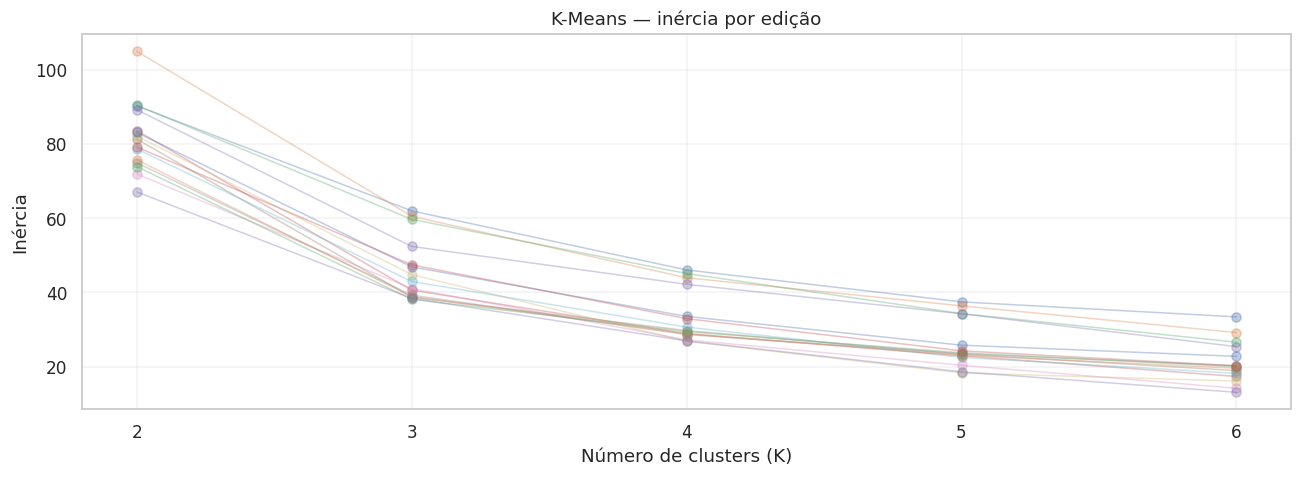

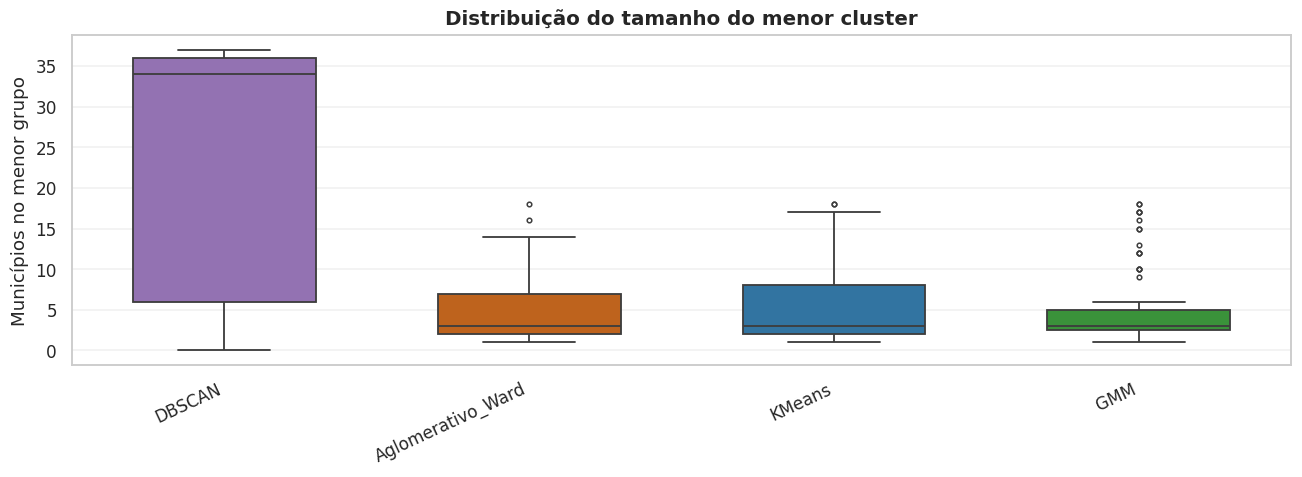

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for ano, dados in resultados_kmeans.groupby("ano"):
    ax.plot(dados["k_solicitado"], dados["inercia"], marker="o", alpha=.35, linewidth=1)
ax.set(title="K-Means — inércia por edição", xlabel="Número de clusters (K)", ylabel="Inércia", xticks=list(K_CANDIDATOS))
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

diagnostico_tamanhos = (resultados_competicao.groupby("algoritmo")
    .agg(
        clusters_mediana=("n_clusters", "median"),
        menor_grupo_min=("n_menor_cluster", "min"),
        menor_grupo_mediana=("n_menor_cluster", "median"),
        maior_grupo_mediana=("n_maior_cluster", "median"),
        proporcao_ruido_mediana=("prop_ruido", "median"),
    ).reset_index()
)


fig, ax = plt.subplots(figsize=(12, 4.5))

sns.boxplot(data=resultados_competicao,x="algoritmo", y="n_menor_cluster",
            hue="algoritmo", order=ordem, hue_order=ordem,
            palette=paleta, legend=False,
            width=0.6, linewidth=1.2, fliersize=3,
            ax=ax)

ax.set_title("Distribuição do tamanho do menor cluster", fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Municípios no menor grupo")
ax.tick_params(axis="x", rotation=25)
plt.setp(ax.get_xticklabels(), ha="right")
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Comentários

A redução da inércia conforme k aumenta é esperada, já que mais centroides diminuem a distância interna dos grupos. Por isso, ela não serve como critério isolado para escolherk.Olhando para o tamanho dos clusters no K-Means e no Ward, a mediana do menor grupo cai de 11–15 municípios em k=2 para 6 em k=3 e apenas 3 em k=4. Como temos só 37 municípios por edição, partir demais o conjunto gera grupos muito pequenos e difíceis de interpretar na prática. Assim, k=2 mantém uma divisão mais equilibrada, enquanto k=3 ou k=4 só valem a pena se trouxerem algum ganho real na leitura dos perfis.

## 6. Comparação controlada: K-Means × Ward

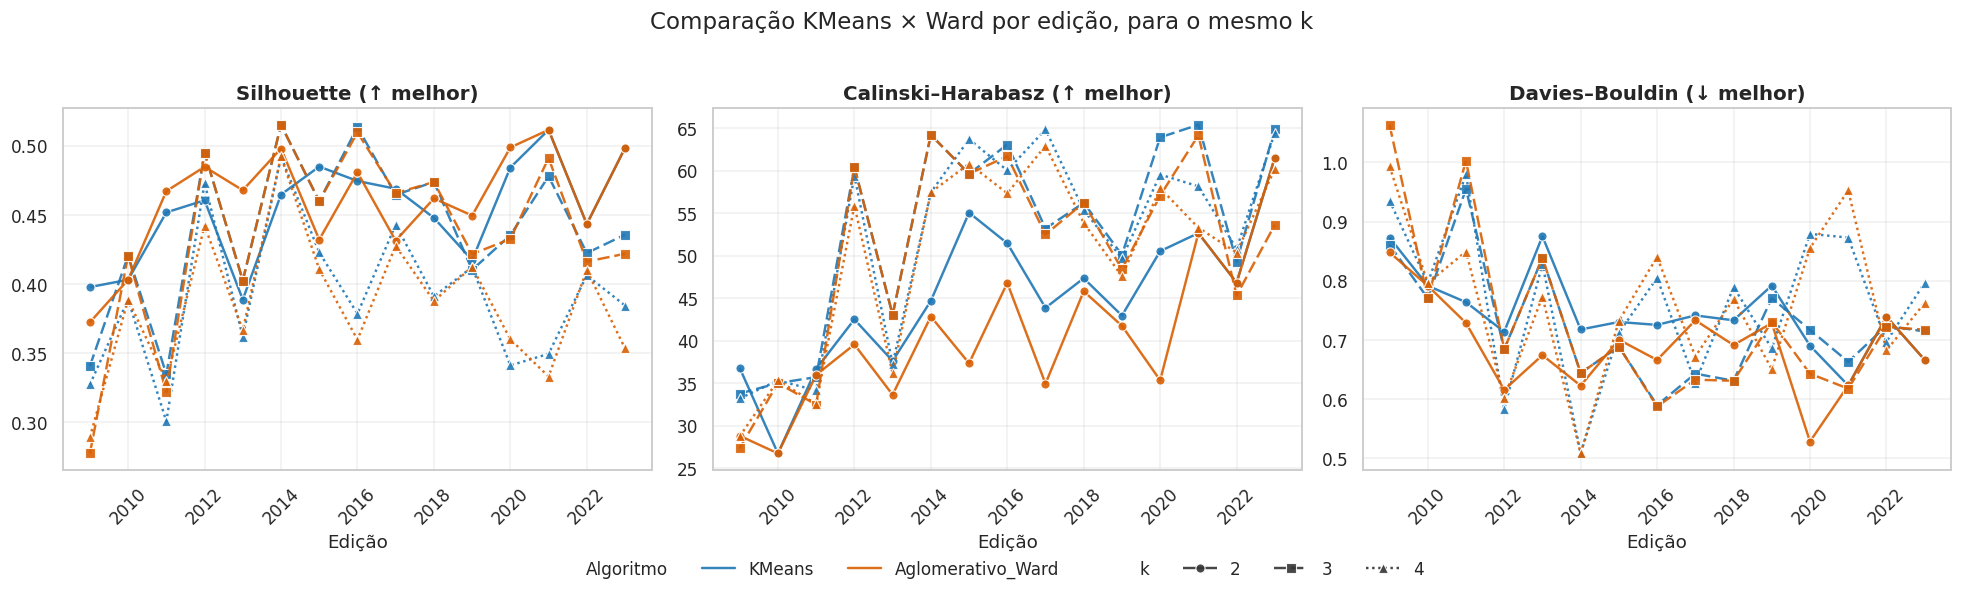

In [7]:
ALGORITMOS_FINALISTAS = ["KMeans", "Aglomerativo_Ward"]

comparacao_mesmo_k = resultados_competicao.loc[resultados_competicao["algoritmo"].isin(ALGORITMOS_FINALISTAS)
    & resultados_competicao["k_solicitado"].isin(K_COMPARACAO)].copy()

# k como inteiro/categoria, para a legenda não mostrar "2.0, 3.0, 4.0"
comparacao_mesmo_k["k_solicitado"] = comparacao_mesmo_k["k_solicitado"].astype(int)
comparacao_mesmo_k["ano"] = comparacao_mesmo_k["ano"].astype(int)

resumo_mesmo_k = (
    comparacao_mesmo_k.groupby(["algoritmo", "k_solicitado"])
    .agg(
        silhouette_mediana=("silhouette", "median"),
        calinski_mediana=("calinski_harabasz", "median"),
        davies_bouldin_mediana=("davies_bouldin", "median"),
        menor_cluster_mediano=("n_menor_cluster", "median"),
        maior_cluster_mediano=("n_maior_cluster", "median"),
        edicoes_avaliaveis=("silhouette", "count"),
    ).reset_index()
)

METRICAS = [
    ("silhouette",        "Silhouette (↑ melhor)"),
    ("calinski_harabasz", "Calinski–Harabasz (↑ melhor)"),
    ("davies_bouldin",    "Davies–Bouldin (↓ melhor)"),
]


# (tamanho do traço, tamanho do espaço); (1, 0) = linha contínua
ESTILOS = {2: (1, 0), 3: (5, 2), 4: (1, 1.5)}
MARCADORES = {2: "o", 3: "s", 4: "^"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax, (metrica, titulo) in zip(axes, METRICAS):
    sns.lineplot(
        data=comparacao_mesmo_k,
        x="ano", y=metrica,
        hue="algoritmo", style="k_solicitado",
        palette=paleta,
        dashes=ESTILOS, markers=MARCADORES,
        markersize=6, linewidth=1.6, alpha=0.9,
        errorbar=None,
        ax=ax, legend=True)
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.set_xlabel("Edição")
    ax.set_ylabel("")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend_.remove()

handles, labels = axes[0].get_legend_handles_labels()
rotulos = ["Algoritmo" if l == "algoritmo" else "k" if l == "k_solicitado" else l for l in labels]

fig.legend(handles, rotulos, loc="lower center", ncol=len(labels),
           frameon=False, bbox_to_anchor=(0.5, -0.04))

fig.suptitle("Comparação KMeans × Ward por edição, para o mesmo k", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()



### Comentários

Na comparação com o mesmo número de grupos, K=2 apresenta as maiores Silhouettes medianas para os dois métodos: 0,4673 em Ward e 0,4606 em K-Means. Para K=3, os valores ficam próximos (0,4327 e 0,4358, respectivamente). Em K=4, a Silhouette cai para aproximadamente 0,388 em ambos.

As métricas não apontam um vencedor absoluto: Ward tem Silhouette e Davies–Bouldin ligeiramente melhores em K=2, enquanto K-Means apresenta valores superiores de Calinski–Harabasz nas três configurações. A escolha precisa, portanto, considerar a estabilidade e a distribuição dos grupos, além das métricas de separação.

## 7. Sensibilidade a perturbações

O teste adiciona ruído gaussiano às variáveis padronizadas e compara a partição perturbada com a partição original por meio do Adjusted Rand Index (ARI). O procedimento avalia sensibilidade às pequenas alterações nos dados, não estabilidade por reamostragem.

In [8]:
N_REPETICOES_ESTABILIDADE = 100
NIVEIS_RUIDO = [0.05, 0.10, 0.20]
resultados_estabilidade = []

for ano in ANOS:
    X_base = MATRIZES_ANUAIS[ano]["X_scaled"]
    modelos_base = {
        "KMeans": {k: KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_base) for k in K_COMPARACAO},
        "Aglomerativo_Ward": {k: AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_base) for k in K_COMPARACAO},
    }
    for algoritmo in ALGORITMOS_FINALISTAS:
        for k in K_COMPARACAO:
            for nivel_ruido in NIVEIS_RUIDO:
                for repeticao in range(N_REPETICOES_ESTABILIDADE):
                    #seed = RANDOM_STATE + ano * 10000 + k * 1000 + ALGORITMOS_FINALISTAS.index(algoritmo) * 100 + NIVEIS_RUIDO.index(nivel_ruido) * 10 + repeticao
                    seed = RANDOM_STATE + ano * 1_000_000+ k * 10_000+ ALGORITMOS_FINALISTAS.index(algoritmo) * 1_000+ NIVEIS_RUIDO.index(nivel_ruido) * 100+ repeticao
                    rng = np.random.default_rng(seed)
                    X_perturbado = X_base + rng.normal(0, nivel_ruido, X_base.shape)
                    if algoritmo == "KMeans":
                        labels = KMeans(n_clusters=k, random_state=seed, n_init=20).fit_predict(X_perturbado)
                    else:
                        labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_perturbado)
                    resultados_estabilidade.append({
                        "ano": ano, "algoritmo": algoritmo, "k": k,
                        "nivel_ruido": nivel_ruido, "repeticao": repeticao,
                        "ari": adjusted_rand_score(modelos_base[algoritmo][k], labels),
                    })

estabilidade_detalhada = pd.DataFrame(resultados_estabilidade)
resumo_estabilidade = (
    estabilidade_detalhada.groupby(["algoritmo", "k", "nivel_ruido"])
    .agg(ari_mediana=("ari", "median"), ari_media=("ari", "mean"), ari_q1=("ari", lambda s: s.quantile(.25)), ari_q3=("ari", lambda s: s.quantile(.75)), ari_minimo=("ari", "min"))
    .reset_index())

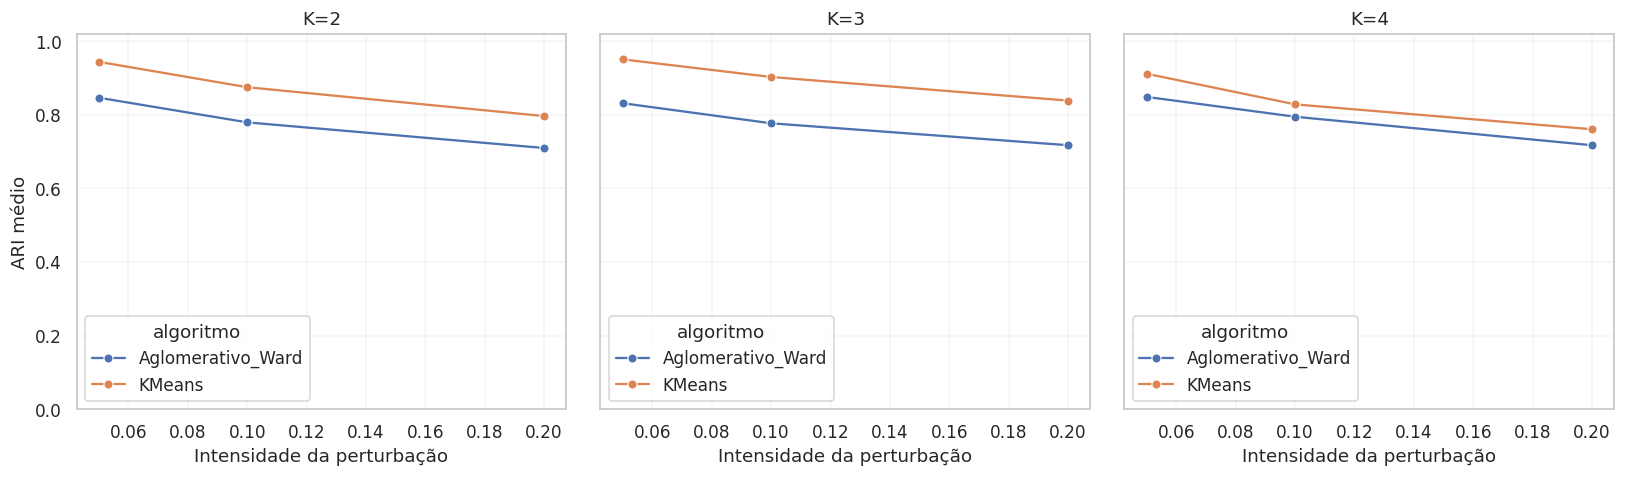

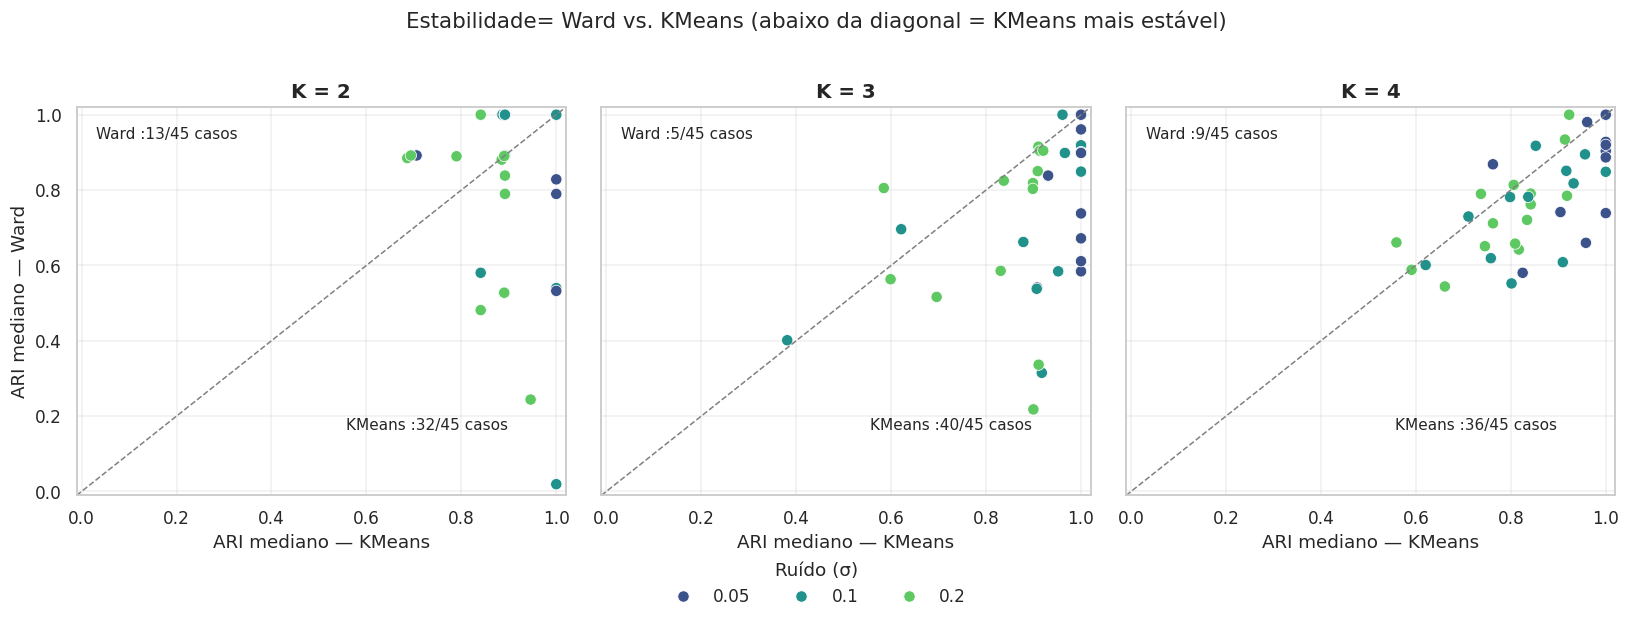

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, k in zip(axes, K_COMPARACAO):
    sns.lineplot(data=resumo_estabilidade.loc[resumo_estabilidade["k"].eq(k)], x="nivel_ruido", y="ari_media", hue="algoritmo", marker="o", ax=ax)
    ax.set(title=f"K={k}", xlabel="Intensidade da perturbação", ylabel="ARI médio")
    ax.set_ylim(0, 1.02); ax.grid(alpha=.2)
plt.tight_layout(); 
plt.show()


# Um ponto por (ano, k, nível de ruído): ARI mediano de cada algoritmo nas 100 repetições
pares = (
    estabilidade_detalhada
    .groupby(["ano", "k", "nivel_ruido", "algoritmo"])["ari"].median()
    .unstack("algoritmo")
    .reset_index()
)
pares["nivel_ruido"] = pares["nivel_ruido"].astype(str)

cores_ruido = dict(zip(
    [str(n) for n in NIVEIS_RUIDO],
    sns.color_palette("viridis", n_colors=len(NIVEIS_RUIDO)),
))

lo = min(pares["KMeans"].min(), pares["Aglomerativo_Ward"].min()) - 0.03
hi = 1.02

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for ax, k in zip(axes, K_COMPARACAO):
    d = pares.loc[pares["k"].eq(k)]

    ax.plot([lo, hi], [lo, hi], color="gray", ls="--", lw=1)  # diagonal: empate
    sns.scatterplot(data=d, x="KMeans", y="Aglomerativo_Ward",
        hue="nivel_ruido", hue_order=list(cores_ruido), palette=cores_ruido,
        s=55, edgecolor="white", linewidth=0.5, ax=ax,)

    ward_vence = (d["Aglomerativo_Ward"] > d["KMeans"]).sum()
    ax.text(0.04, 0.95, f"Ward :{ward_vence}/{len(d)} casos",
            transform=ax.transAxes, va="top", fontsize=10)
    ax.text(0.55, 0.2, f"KMeans :{len(d)-ward_vence}/{len(d)} casos",
            transform=ax.transAxes, va="top", fontsize=10)

    ax.set_title(f"K = {k}", fontsize=13, fontweight="bold")
    ax.set_xlabel("ARI mediano — KMeans")
    ax.set_ylabel("ARI mediano — Ward" if ax is axes[0] else "")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    #ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend_.remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Ruído (σ)", loc="lower center",
           ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.09))
fig.suptitle("Estabilidade= Ward vs. KMeans (abaixo da diagonal = KMeans mais estável)",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Comentários

O K-Means apresentou ARI médio superior ao Ward em todas as combinações de K e intensidade de perturbação, como mostra a tabela abaixo:

| Número de grupos | Ruído | K-Means (ARI médio) | Ward (ARI médio) |
|---:|---:|---:|---:|
| 2 | 0,05 | **0,9517** | 0,8247 |
| 2 | 0,10 | **0,8842** | 0,7836 |
| 2 | 0,20 | **0,7957** | 0,6803 |
| 3 | 0,05 | **0,9431** | 0,8376 |
| 3 | 0,10 | **0,9112** | 0,7879 |
| 3 | 0,20 | **0,8348** | 0,7216 |
| 4 | 0,05 | **0,9184** | 0,8410 |
| 4 | 0,10 | **0,8443** | 0,7821 |
| 4 | 0,20 | **0,7387** | 0,7001 |

A mediana do ARI também foi elevada em diversas combinações, chegando a 1,0, indicando que pelo menos metade das simulações preservou integralmente a partição original em algumas configurações. Entretanto, os valores mínimos e a dispersão dos resultados mostram que a estabilidade não é absoluta, especialmente sob ruído mais intenso. O teste avalia a sensibilidade a perturbações gaussianas nas variáveis padronizadas; não equivale a uma validação por reamostragem nem garante estabilidade diante de outras escolhas metodológicas.

## 8-Conclusão metodológica

A clusterização complementa Q1–Q7 ao sintetizar simultaneamente as cinco disciplinas (Ciências Humanas, Ciências da Natureza, Linguagens, Matemática e Redação) e identificar perfis multidimensionais de municípios, em vez de examinar apenas médias, dispersões ou associações entre variáveis isoladas.

A comparação entre K-Means, Aglomerativo Ward, GMM e DBSCAN demonstrou que a escolha do algoritmo deve considerar conjuntamente as métricas internas de qualidade, a frequência de soluções válidas, o tamanho dos grupos e a estabilidade diante de perturbações.

Na comparação inicial, K-Means, Ward e GMM apresentaram soluções válidas em todas as combinações avaliadas. Entre esses métodos, Ward obteve silhouette mediano de 0,4026, ligeiramente superior ao K-Means (0,3987), enquanto o GMM apresentou 0,3293. O DBSCAN alcançou silhouette mediano de 0,4621, mas produziu apenas 82 soluções válidas entre 270 avaliações (30,37%), com mediana de um único grupo. Portanto, seu resultado de silhouette deve ser interpretado com cautela, pois não representa uma capacidade consistente de formação de agrupamentos úteis para o problema investigado.

A comparação controlada entre K-Means e Ward, utilizando o mesmo número de grupos, mostrou resultados próximos nas métricas de separação. Para K=2, Ward apresentou silhouette mediano de 0,4673, enquanto o K-Means obteve 0,4606. Para K=3, os valores foram 0,4327 e 0,4358, respectivamente. Em K=4, ambos apresentaram valores próximos de 0,388. Assim, embora Ward tenha apresentado pequena vantagem em algumas configurações, não houve superioridade uniforme nas métricas internas.

O diagnóstico dos tamanhos dos grupos também favoreceu K=2. No K-Means, a mediana do menor grupo foi de aproximadamente 15 municípios, contra 11 no Ward. Para K=3, esse valor caiu para aproximadamente 6 municípios, e para K=4, para 3 municípios. Considerando a coorte de apenas 37 municípios, o aumento do número de grupos tende a produzir subdivisões menores, dificultando a interpretação dos perfis.

**Síntese da avaliação dos algoritmos**

| Critério | Resultado observado | Implicação metodológica |
|---|---|---|
| Métricas internas | K-Means e Ward apresentaram resultados próximos; Ward teve pequena vantagem em algumas configurações. | Não há superioridade uniforme de um método pela separação interna. |
| Soluções válidas | K-Means, Ward e GMM apresentaram 100% de soluções válidas; DBSCAN, 30,37%. | DBSCAN mostrou menor consistência na formação de grupos úteis. |
| Equilíbrio dos grupos | K-Means com K=2 apresentou mediana de 15 municípios no menor grupo, contra 11 no Ward. | K-Means favorece uma divisão mais equilibrada. |
| Estabilidade | K-Means apresentou ARI médio superior ao Ward nas nove combinações de K e ruído avaliadas. | Evidência favorável ao K-Means diante das perturbações simuladas. |
| Interpretabilidade | K=2 produz uma divisão mais simples e grupos menos fragmentados. | Favorece a caracterização e o acompanhamento dos perfis municipais. |

**Estabilidade diante das perturbações**

O teste de sensibilidade foi realizado com 100 repetições independentes para cada edição, algoritmo, número de grupos e intensidade de ruído. Foram utilizados três níveis de perturbação gaussiana nas variáveis padronizadas: 0,05, 0,10 e 0,20.

O K-Means apresentou ARI médio superior ao Ward em todas as combinações avaliadas. Para K=2, as médias foram de 0,9517, 0,8842 e 0,7957, respectivamente, enquanto o Ward apresentou 0,8247, 0,7836 e 0,6803.

| Número de grupos | Ruído | K-Means (ARI médio) | Ward (ARI médio) |
|---:|---:|---:|---:|
| 2 | 0,05 | **0,9517** | 0,8247 |
| 2 | 0,10 | **0,8842** | 0,7836 |
| 2 | 0,20 | **0,7957** | 0,6803 |
| 3 | 0,05 | **0,9431** | 0,8376 |
| 3 | 0,10 | **0,9112** | 0,7879 |
| 3 | 0,20 | **0,8348** | 0,7216 |
| 4 | 0,05 | **0,9184** | 0,8410 |
| 4 | 0,10 | **0,8443** | 0,7821 |
| 4 | 0,20 | **0,7387** | 0,7001 |

Além das médias superiores, o K-Means apresentou menor dispersão dos valores de ARI para K=2 nos três níveis de ruído. Os resultados indicam menor sensibilidade média às perturbações simuladas, embora não representem estabilidade absoluta. A comparação entre 20 e 100 repetições também manteve a mesma conclusão geral, reforçando a consistência do resultado observado.

**Decisão para a aplicação**

Com base no conjunto de evidências, foi selecionado o **K-Means com K=2** para a aplicação no notebook Q8B. A decisão considera conjuntamente:

- A qualidade de separação competitiva em relação ao Ward;
- A maior estabilidade média diante das perturbações simuladas;
- A menor dispersão dos valores de ARI para K=2;
- O maior equilíbrio dos tamanhos dos grupos em comparação ao Ward;
- A simplicidade e a interpretabilidade de uma solução com dois perfis.

O K=3 permanece como alternativa complementar, pois apresentou estabilidade competitiva, especialmente no K-Means. Entretanto, sua utilização implica maior fragmentação dos municípios e grupos menores, sem evidência suficiente para justificar sua adoção como solução principal.

A interpretação dos perfis, suas características e sua evolução municipal pertencem exclusivamente ao notebook Q8B.

**Limitações**

- A coorte inclui 37 municípios com dados completos nas 15 edições; não representa todos os municípios paraenses.
- As métricas internas não comprovam a existência de grupos naturais.
- A padronização independente por edição produz perfis relativos ao conjunto de municípios de cada ano, não permitindo interpretar diretamente as diferenças entre anos como mudanças absolutas de desempenho.
- A clusterização é exploratória e descritiva; não identifica causas do desempenho.
- O teste de perturbação avalia a sensibilidade às alterações gaussianas simuladas nas variáveis padronizadas. Não equivale a uma validação por reamostragem nem garante estabilidade diante de outras amostras ou especificações metodológicas.
- A seleção do algoritmo e do número de grupos depende dos critérios adotados e do objetivo analítico, não constituindo uma solução universal.

### Encaminhamento

O notebook Q8B aplicará o método selecionado — K-Means com K=2 — às 15 edições, apresentando a caracterização dos perfis, sua distribuição municipal e as transições temporais entre 2009 e 2023. A análise permitirá investigar a persistência e as mudanças de posição relativa dos municípios ao longo do período.

## ANEX0- Save resultados

In [10]:
# Síntese compacta para documentar a decisão e exportar os resultados.
print("Coorte:", n_municipios, "municípios |", len(ANOS), "edições |", len(DISCIPLINAS), "disciplinas")
print("A comparação controlada e os testes de estabilidade foram concluídos.")

DIRETORIO_SAIDA = Path(PROJECT_ROOT) / "data" / "reports" / "clustering_metodologia" / f"uf={UF_PROCESSAMENTO}" / f"ref={TIPO_REFERENCIA}"
DIRETORIO_SAIDA.mkdir(parents=True, exist_ok=True)
saidas = {
    "resultados_competicao_2009_2023.csv": resultados_competicao,
    "resumo_algoritmos_2009_2023.csv": resumo_algoritmos,
    "diagnostico_tamanhos_2009_2023.csv": diagnostico_tamanhos,
    "comparacao_kmeans_ward_mesmo_k_2009_2023.csv": comparacao_mesmo_k,
    "resumo_kmeans_ward_mesmo_k_2009_2023.csv": resumo_mesmo_k,
    "estabilidade_perturbacoes_detalhada_2009_2023.csv": estabilidade_detalhada,
    "resumo_estabilidade_perturbacoes_2009_2023.csv": resumo_estabilidade,
}
for nome, tabela in saidas.items():
    tabela.to_csv(DIRETORIO_SAIDA / nome, sep=";", index=False, encoding="utf-8-sig")
print(f"Resultados exportados para: {DIRETORIO_SAIDA}")

Coorte: 37 municípios | 15 edições | 5 disciplinas
A comparação controlada e os testes de estabilidade foram concluídos.
Resultados exportados para: /home/akel/PycharmProjects/Projeto_ENEM/data/reports/clustering_metodologia/uf=PA/ref=ESC
